# 3D Print SPM

## Individual proof of concept commands

In [23]:
import serial
import time

# 1. Identify your Prusa's port (replace XXXX with your actual port numbers)
serial_port = '/dev/cu.usbmodem21201' 
baud_rate = 115200

try:
    # 2. Open the serial connection
    print("Connecting to Prusa...")
    # dsrdtr=True prevents some systems from triggering a continuous reset loop
    prusa = serial.Serial(serial_port, baud_rate, timeout=2, dsrdtr=True)
    
    # 3. CRITICAL: Wait for the printer to reboot and become ready
    time.sleep(3) 
    
    # Clear the initial bootup text from the buffer
    prusa.reset_input_buffer()

    # 4. Send the Home command (G28)
    # Commands must end with a newline (\n) and be encoded to bytes
    command = "G28 W\n"
    print(f"Sending command: {command.strip()}")
    prusa.write(command.encode('utf-8'))

    # 5. Read the response until the printer says 'ok'
    while True:
        line = prusa.readline().decode('utf-8').strip()
        if line:
            print(f"Printer: {line}")
        if "ok" in line:
            print("Command executed successfully!")
            break

except Exception as e:
    print(f"Error: {e}")

finally:
    # 6. Always close the port when finished
    if 'prusa' in locals() and prusa.is_open:
        prusa.close()
        print("Connection closed.")

Connecting to Prusa...
Sending command: G28 W
Printer: FSensor ENABLED
Printer: echo:SD init fail
Printer: // action:dump_available
Printer: echo:SD init fail
Printer: tmc2130_home_enter(axes_mask=0x04)
Printer: echo:busy: processing
Printer: tmc2130_home_exit tmc2130_sg_homing_axes_mask=0x04
Printer: tmc2130_home_enter(axes_mask=0x01)
Printer: 0 step=45 mscnt= 733
Printer: tmc2130_goto_step 0 61 2 1000
Printer: tmc2130_home_exit tmc2130_sg_homing_axes_mask=0x01
Printer: tmc2130_home_enter(axes_mask=0x02)
Printer: echo:busy: processing
Printer: 0 step= 2 mscnt=  33
Printer: tmc2130_goto_step 1 1 2 1000
Printer: tmc2130_home_exit tmc2130_sg_homing_axes_mask=0x02
Printer: echo:busy: processing
Printer: ok
Command executed successfully!
Connection closed.


## MVP Scan loop

In [ ]:

import re
import csv
import numpy as np
from matplotlib import pyplot as plt

In [63]:


# --- CONFIGURATION ---
SERIAL_PORT = '/dev/cu.usbmodem21201'
BAUD_RATE = 115200    # Prusa MK3S+ standard baud rate

# Define your scan grid boundaries (in mm)
# !! Double-check your hardware clearances before running !!
X_START, X_END, X_STEP = 58, 103, 3   # Scans from 50mm to 150mm every 10mm
Y_START, Y_END, Y_STEP = 58, 103, 3
Z_CLEARANCE = 8  # Safe height to lift between probes

# --- GENERATE GRID COORDINATES ---
grid_points = []
for y in range(Y_START, Y_END + Y_STEP, Y_STEP):
    for x in range(X_START, X_END + X_STEP, X_STEP):
        grid_points.append((x, y))

In [64]:


# --- SERIAL COMMUNICATION HELPER ---
def send_command(ser, cmd):
    """Sends a G-code command and waits for the 'ok' response."""
    ser.write(f"{cmd}\n".encode('utf-8'))
    # print(f"Sent: {cmd}") # Debug
    
    response_lines = []
    while True:
        line = ser.readline().decode('utf-8').strip()
        if line:
            response_lines.append(line)
        if "ok" in line.lower():
            break
    return response_lines

def is_pinda_triggered(ser):
    """Queries M119 and checks if the Z-probe/PINDA is currently triggered."""
    lines = send_command(ser, "M119")
    for line in lines:
        # Looking for something like "z_probe: TRIGGERED" or "z_min: TRIGGERED"
        if "z_" in line.lower() and "triggered" in line.lower():
            return True
    return False

scan_data = []

# --- MAIN SCANNING LOOP ---
print(f"Connecting to Prusa on {SERIAL_PORT}...")
try:
    # Open serial port with a timeout to prevent infinite hanging
    ser = serial.Serial(SERIAL_PORT, BAUD_RATE, timeout=2)
    time.sleep(2) # Wait for Prusa bootloader/reboot handshake
    ser.reset_input_buffer()

    print("Homing printer (G28)... Please ensure bed is clear.")
    send_command(ser, "G28 W")
    send_command(ser, "G90") # Absolute positioning
    
    # Lift to a safe starting height
    send_command(ser, f"G01 Z{Z_CLEARANCE} F1500")
    send_command(ser, "M400")

    # Regular expression to parse the G30 output
    # Prusa standard output format: "Bed X: 50.00 Y: 50.00 Z: 0.15"
    pinda_regex = re.compile(r"Bed\s+X:\s*([\d\.-]+)\s+Y:\s*([\d\.-]+)\s+Z:\s*([\d\.-]+)")

    results = []

    print(f"Starting scan of {len(grid_points)} points...")
    for idx, (x, y) in enumerate(grid_points):
        print(f"[{idx+1}/{len(grid_points)}] Scanning point X:{x} Y:{y}...")
        
        # 1. Travel to coordinate at full clearance height (Absolute Mode)
        send_command(ser, "G90") 
        send_command(ser, f"G01 X{x} Y{y} Z{Z_CLEARANCE} F6000")
        send_command(ser, "M400")
        
        # 2. Enter Micro-Stepping Descent (Relative Mode)
        send_command(ser, "G91") 
        cantilever_touched = False
        total_descended = 0
        
        # We step down 0.1mm at a time. To go down 9mm max, we loop up to 90 times.
        for step in range(90):
            # Check sensor state BEFORE moving down further
            if is_pinda_triggered(ser):
                cantilever_touched = True
                break
                
            # If we've traveled way too far down without touching anything, trigger safety stop
            if total_descended >= (Z_CLEARANCE + 2): 
                print("   ⚠️ Safety Stop: Exceeded max scan depth without contact!")
                break
                
            # Execute a tiny, safe 0.5mm step down
            # F600 is slow and controlled, ensuring minimal mechanical momentum
            send_command(ser, "G01 Z-0.1 F1500")
            total_descended += 0.1

        results.append({"X": x, "Y": y, "Z": Z_CLEARANCE-total_descended})
        print({"X": x, "Y": y, "Z": Z_CLEARANCE-total_descended})

        # 4. Reset to top clearance height before translating to the next point
        send_command(ser, "G90")
        send_command(ser, f"G01 Z{Z_CLEARANCE} F6000")

    scan_data.append(results)
    
    print("Done!")

except serial.SerialException as e:
    print(f"Serial Error: {e}")
except KeyboardInterrupt:
    print("\nScan interrupted by user! Stopping motors.")
    if 'ser' in locals() and ser.is_open:
        ser.write(b"M112\n") # Emergency stop G-code if you hit Ctrl+C
        ser.close()
finally:
    if 'ser' in locals() and ser.is_open:
        ser.close()

Connecting to Prusa on /dev/cu.usbmodem21201...
Homing printer (G28)... Please ensure bed is clear.
Starting scan of 256 points...
[1/256] Scanning point X:58 Y:58...
{'X': 58, 'Y': 58, 'Z': 2.8000000000000025}
[2/256] Scanning point X:61 Y:58...
{'X': 61, 'Y': 58, 'Z': 2.8000000000000025}
[3/256] Scanning point X:64 Y:58...
{'X': 64, 'Y': 58, 'Z': 2.600000000000003}
[4/256] Scanning point X:67 Y:58...
{'X': 67, 'Y': 58, 'Z': 2.600000000000003}
[5/256] Scanning point X:70 Y:58...
{'X': 70, 'Y': 58, 'Z': 2.600000000000003}
[6/256] Scanning point X:73 Y:58...
{'X': 73, 'Y': 58, 'Z': 2.600000000000003}
[7/256] Scanning point X:76 Y:58...
{'X': 76, 'Y': 58, 'Z': 2.600000000000003}
[8/256] Scanning point X:79 Y:58...
{'X': 79, 'Y': 58, 'Z': 2.600000000000003}
[9/256] Scanning point X:82 Y:58...
{'X': 82, 'Y': 58, 'Z': 2.600000000000003}
[10/256] Scanning point X:85 Y:58...
{'X': 85, 'Y': 58, 'Z': 2.600000000000003}
[11/256] Scanning point X:88 Y:58...
{'X': 88, 'Y': 58, 'Z': 0.9000000000000

In [65]:
image = [i["Z"] for i in results]
image = np.array(image)

In [66]:
image.shape

(256,)

In [67]:
image = image.reshape((16, 16))

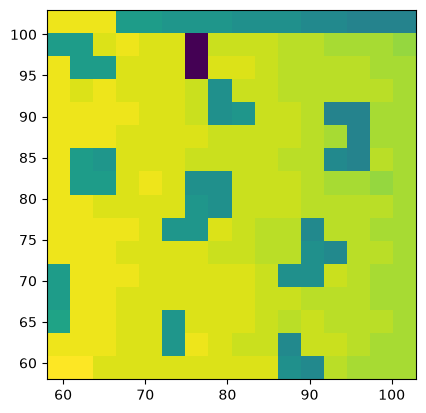

In [68]:
plt.imshow(image, extent=(X_START, X_END, Y_START, Y_END), origin='lower')
plt.show()

In [70]:
image.min()

np.float64(-0.999999999999984)